<div style='background-color:#EEF4F7; border-left:4px solid #6F8996; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Homework 10 - The Second Half of CRISP-DM</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Deadline: November 30th, 2026 at noon (12:00 Europe/Tallinn time)</strong></p>

</div>

Note! This homework is submitted as groups. One group member submits on behalf of the whole team.

Not every question fits every project. If a question does not apply to yours, first adapt it to your project, and then answer it.

Most questions have an empty code cell above the answer box. Use it if code, a table or a plot helps your answer, and leave it empty if it does not - for most questions a written answer on its own is enough. Where a question asks you to show the data or a graph, use the cell.

In the previous project homework (HW7) you worked out what your project is about and what is in your data. This one takes you through the rest of CRISP-DM: preparing the data, applying a method, judging the result, and getting it ready for other people to see.

**Your project does not have to be finished by the deadline of this homework.** It has to be finished by the poster deadline, one week later. The point of the questions below is to guide and help you finish your project on time.

Where this homework sits in the process:

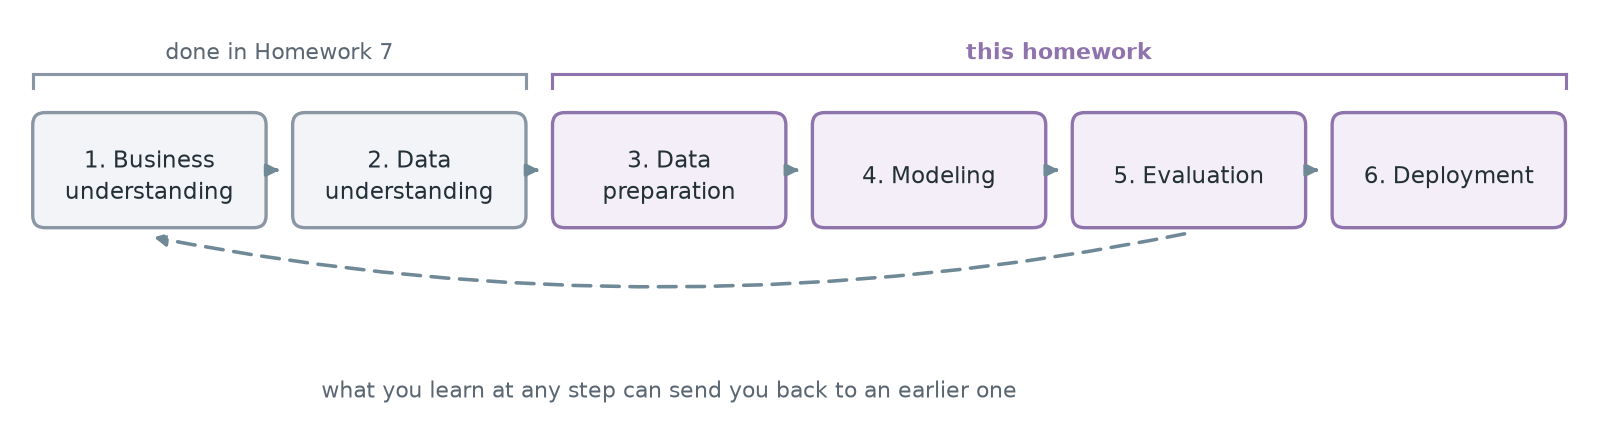

**Your project**

State these again, so that this notebook can be read on its own.

**Group ID and topic:** <span>H1 - KAGGLE-HISTORICAL FLIGHT PRICES.</span>

**Team members:** <span>Kerreth Arula, Nazar Zavrin, Oliver Albert Hallik.</span>

**Repository URL:** <span style="color:#B3261E;">https://github.com/NazarZavrinUT/Introduction_to_Data_Science_project</span>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">1. Data preparation (0.5 points)</h1>

</div>

This is **step 3** of CRISP-DM. The aim is to get from the raw data to a table you can actually work with, and to be able to say exactly what you changed and why. Someone reading your repository later should be able to repeat every one of those steps.

**a. Show the prepared data.**

Show the table your analysis runs on - the one you ended up with after cleaning, not the raw file you started from. Print its shape, the column names and the first few rows.

The rest of this task asks how you got from the raw data to this, so it helps to have it in front of you first.

## We will show the initial file and how we initally cleaned it, as well as the finished feature file alongside it

In [4]:
# pip install kagglehub
# pip install pyarrow
from pathlib import Path
import pandas as pd
#import kagglehub
import os

initial_file_name = "flights_clean.parquet"
feature_file_name = "features.parquet"
#path = kagglehub.dataset_download("daniilchuhai/flights-test", path=file_name)
# print("Path to the dataset file:", path)
new_path_1 = Path(Path.cwd(), initial_file_name)
new_path_2 = Path(Path.cwd(), feature_file_name)
print("New path to the dataset file:", new_path_1)
#os.replace(path, new_path)

df = pd.read_parquet(new_path_1)
print(df.shape)
df.iloc[0]

New path to the dataset file: C:\Users\kerre\Desktop\projects\DSproject\Introduction_to_Data_Science_project\flights_clean.parquet
(20496381, 18)


itinerary_id           FR8257-2025-05-03-RIX-PRG
price_datetime        2025-05-02 22:58:11.409667
price                                  87.989998
departure_date               2025-05-03 00:00:00
region_from                              Baltics
region_to                                Eastern
is_best                                        1
airline_code                                  FR
flight_number                             FR8257
airline_name                             Ryanair
aircraft                              Boeing 737
src                                          RIX
dst                                          PRG
departure_datetime           2025-05-03 09:20:00
arrival_datetime             2025-05-03 10:20:00
travel_time                                  120
emissions                                92686.0
days_to_departure                              1
Name: 0, dtype: object

In [6]:
df_features = pd.read_parquet(new_path_2)
print(df_features.shape)
df_features.iloc[0]

(20381571, 32)


itinerary_id           FR8257-2025-05-03-RIX-PRG
flight_number                             FR8257
price                                  87.989998
log_price                               4.477223
split                                      train
price_outlier                                  0
price_datetime        2025-05-02 22:58:11.409667
departure_date               2025-05-03 00:00:00
region_from                              Baltics
region_to                                Eastern
is_best                                        1
airline                                  Ryanair
aircraft                              Boeing 737
src                                          RIX
dst                                          PRG
departure_datetime           2025-05-03 09:20:00
arrival_datetime             2025-05-03 10:20:00
travel_time                                  120
emissions                                92686.0
days_to_departure                              1
distance_km         

### Missing values

In [7]:
display(df.isna().sum())
display(df.shape)

itinerary_id               0
price_datetime             0
price                      0
departure_date             0
region_from                0
region_to                  0
is_best                    0
airline_code               0
flight_number              0
airline_name               0
aircraft               18954
src                        0
dst                        0
departure_datetime         0
arrival_datetime           0
travel_time                0
emissions             113441
days_to_departure          0
dtype: int64

(20496381, 18)

In [8]:
display(df_features.isna().sum())
display(df_features.shape)

itinerary_id          0
flight_number         0
price                 0
log_price             0
split                 0
price_outlier         0
price_datetime        0
departure_date        0
region_from           0
region_to             0
is_best               0
airline               0
aircraft              0
src                   0
dst                   0
departure_datetime    0
arrival_datetime      0
travel_time           0
emissions             0
days_to_departure     0
distance_km           0
route                 0
emissions_per_km      0
dep_hour              0
dep_weekday           0
dep_month             0
dep_is_weekend        0
is_christmas          0
is_new_year           0
is_summer             0
search_weekday        0
search_hour           0
dtype: int64

(20381571, 32)

In [9]:
data = df.dropna().copy()

In [10]:
display(data.isna().sum())
display(data.shape)
print("Removed rows number:", len(df) - len(data))

itinerary_id          0
price_datetime        0
price                 0
departure_date        0
region_from           0
region_to             0
is_best               0
airline_code          0
flight_number         0
airline_name          0
aircraft              0
src                   0
dst                   0
departure_datetime    0
arrival_datetime      0
travel_time           0
emissions             0
days_to_departure     0
dtype: int64

(20381571, 18)

Removed rows number: 114810


### Duplicates

In [11]:
print(len(data[data.duplicated()]))

0


### Impossible or inconsistent values

In [6]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use("ggplot")

price
1400.040039     14
1400.069946      2
1400.079956      2
1400.089966      1
1400.119995      1
                ..
15734.179688     1
15753.669922     1
16807.240234     1
18121.919922     1
19345.810547     1
Name: count, Length: 48359, dtype: int64
travel_time
601       65
602        2
603       50
604      204
605    20474
       ...  
775     1049
780       77
785     5254
790      425
810     1533
Name: count, Length: 81, dtype: int64
emissions
100003.0     346
100004.0     572
100008.0      70
100009.0      89
100010.0     256
            ... 
2310024.0     15
2331632.0      6
2441624.0      4
2462840.0     10
2548305.0      1
Name: count, Length: 66557, dtype: int64


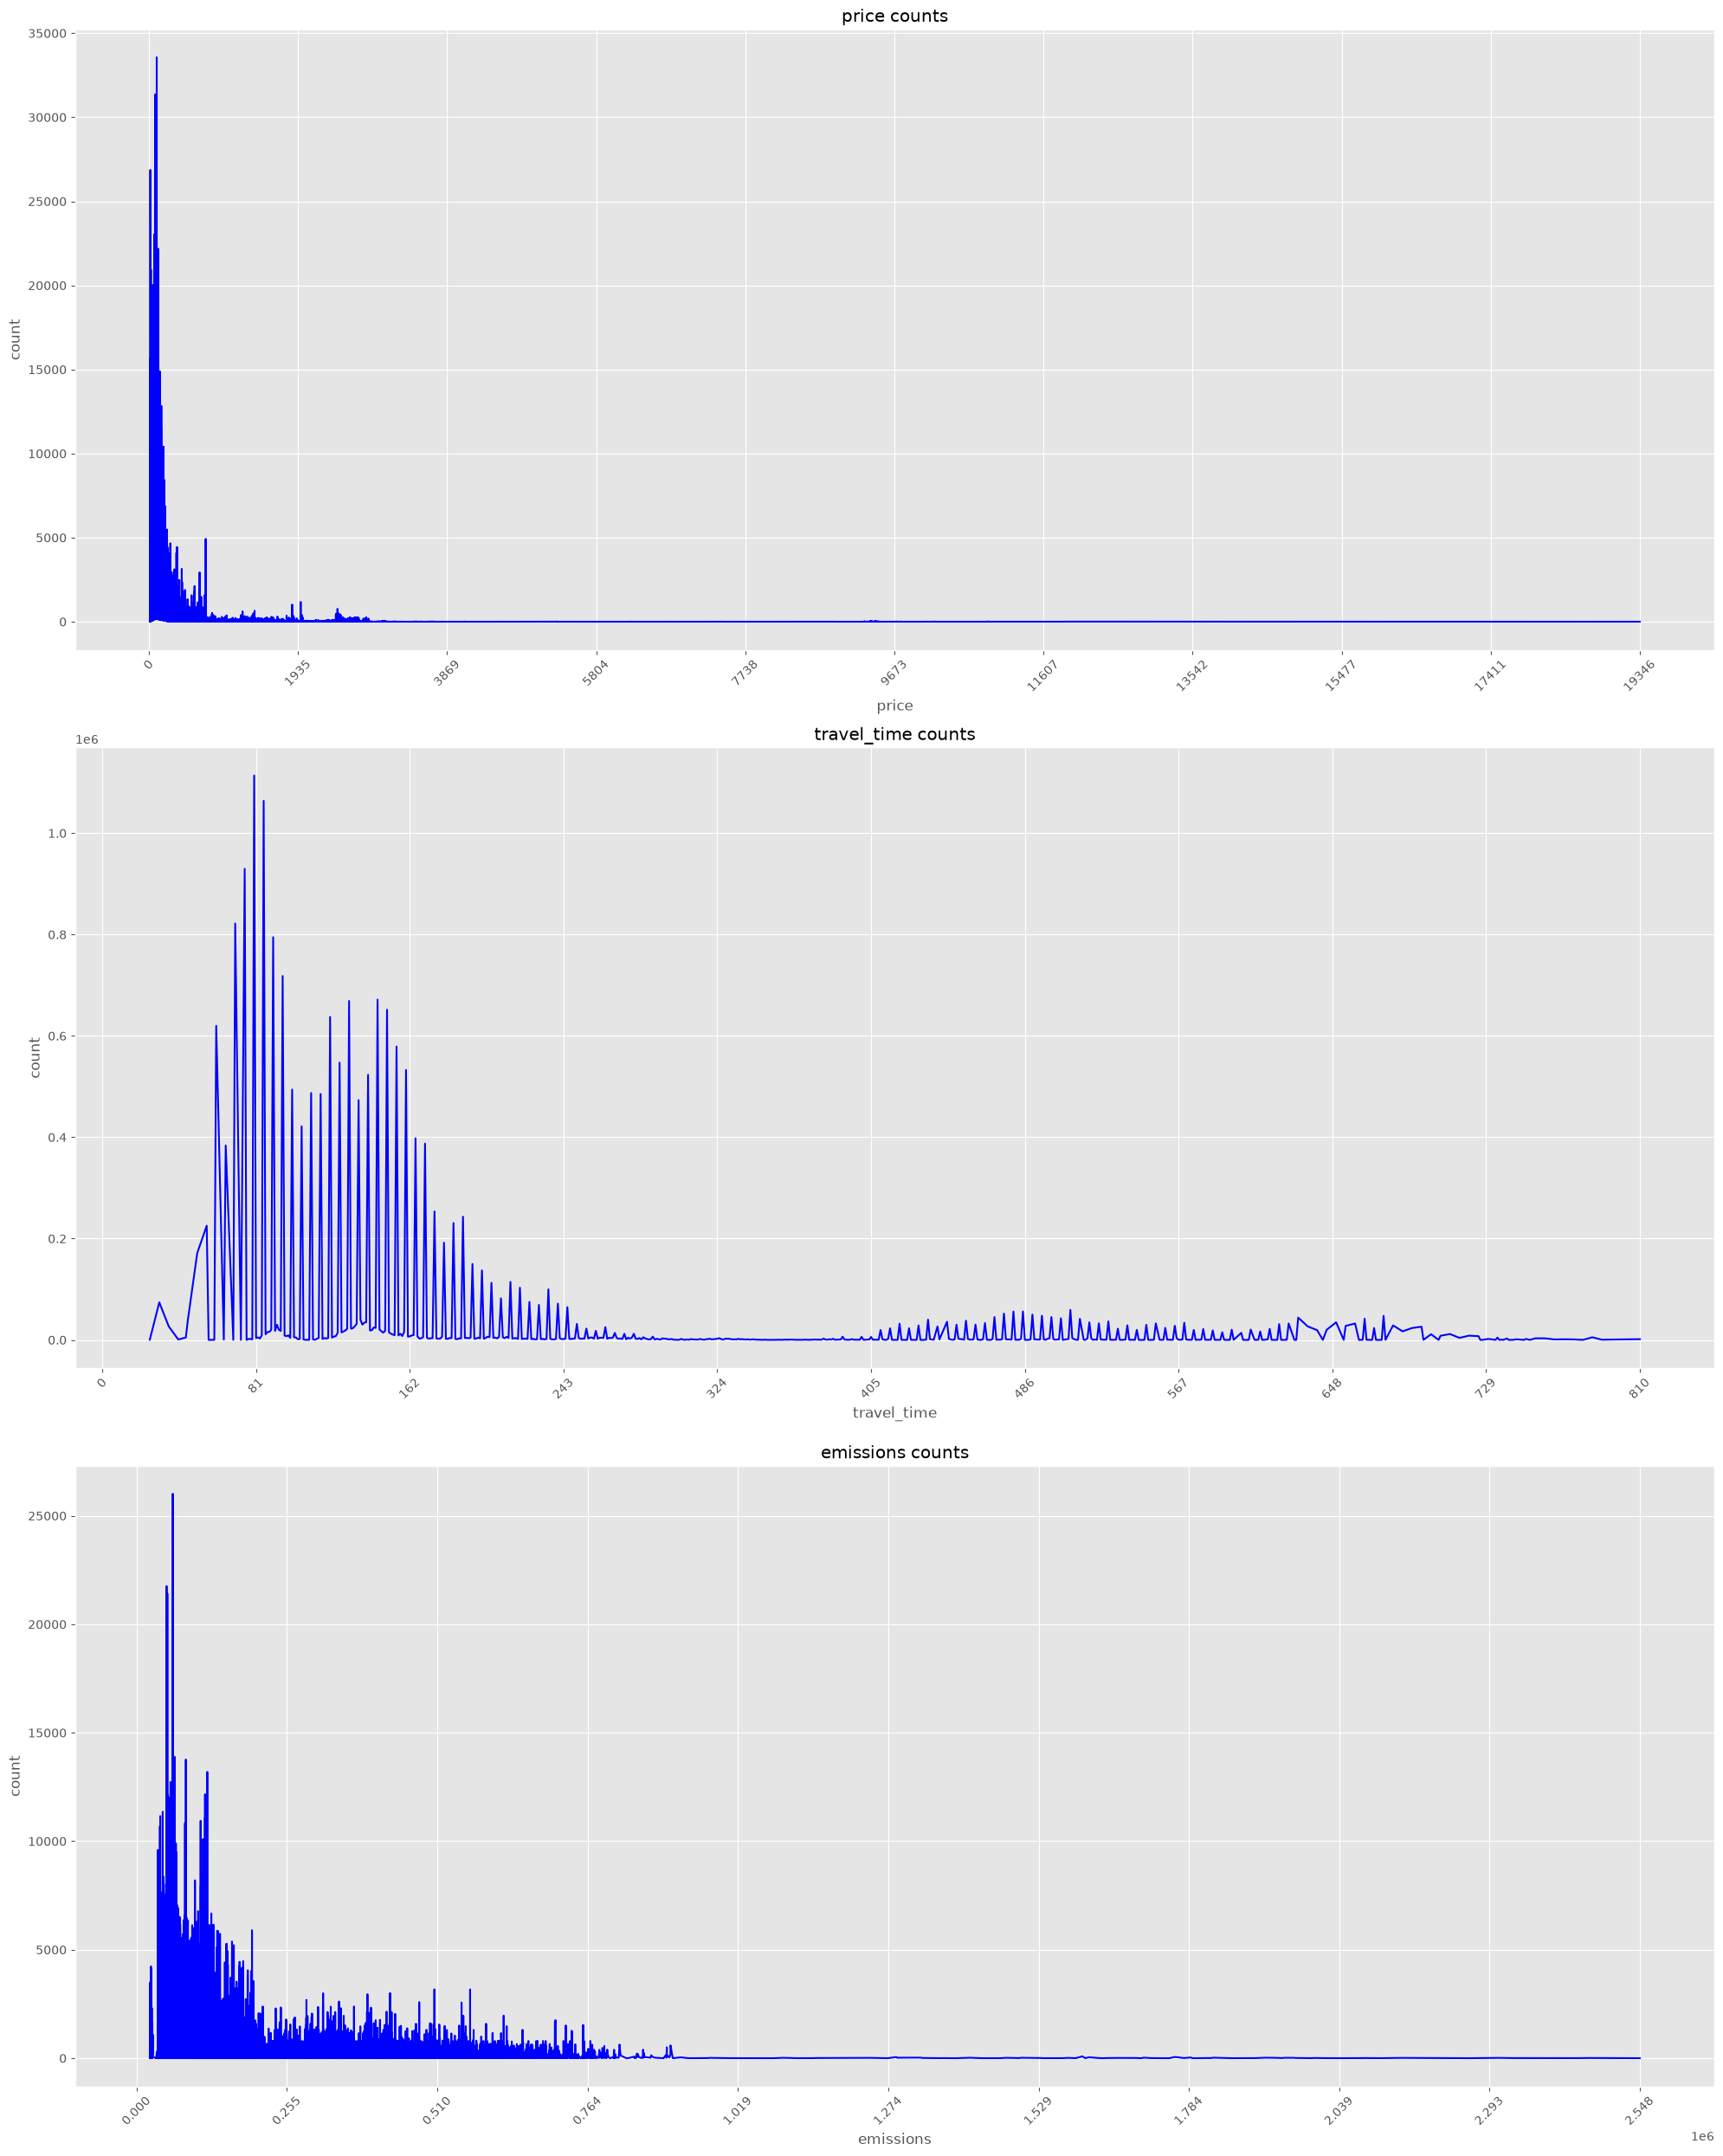

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(20, 25))
columns_and_values_to_check = {'price': 1400, 'travel_time': 60 * 10, 'emissions': 10 * 10000}
for i, column in enumerate(columns_and_values_to_check.keys()):
    data[column].value_counts().sort_index().plot(ax=axes[i], color='blue', grid=True,
        xticks=np.arange(0, data[column].max() * 1.01, data[column].max() / 10), rot=45,
        xlabel=column, ylabel='count', title=column + ' counts')
    print(data[column][data[column] > columns_and_values_to_check[column]].value_counts().sort_index())
fig.tight_layout()
plt.show()

### Data types

In [8]:
display(data.info())

<class 'pandas.DataFrame'>
Index: 20381571 entries, 0 to 20496380
Data columns (total 18 columns):
 #   Column              Dtype         
---  ------              -----         
 0   itinerary_id        str           
 1   price_datetime      datetime64[ns]
 2   price               float32       
 3   departure_date      datetime64[ns]
 4   region_from         str           
 5   region_to           str           
 6   is_best             int64         
 7   airline_code        str           
 8   flight_number       str           
 9   airline_name        str           
 10  aircraft            str           
 11  src                 str           
 12  dst                 str           
 13  departure_datetime  datetime64[ns]
 14  arrival_datetime    datetime64[ns]
 15  travel_time         int64         
 16  emissions           float64       
 17  days_to_departure   int64         
dtypes: datetime64[ns](4), float32(1), float64(1), int64(3), str(9)
memory usage: 4.3 GB


None

In [12]:
display(df_features.info())

<class 'pandas.DataFrame'>
RangeIndex: 20381571 entries, 0 to 20381570
Data columns (total 32 columns):
 #   Column              Dtype         
---  ------              -----         
 0   itinerary_id        str           
 1   flight_number       category      
 2   price               float32       
 3   log_price           float32       
 4   split               category      
 5   price_outlier       int8          
 6   price_datetime      datetime64[ns]
 7   departure_date      datetime64[ns]
 8   region_from         category      
 9   region_to           category      
 10  is_best             int8          
 11  airline             category      
 12  aircraft            category      
 13  src                 category      
 14  dst                 category      
 15  departure_datetime  datetime64[ns]
 16  arrival_datetime    datetime64[ns]
 17  travel_time         int16         
 18  emissions           float32       
 19  days_to_departure   int16         
 20  distance_km

None

In [9]:
data.to_parquet("cleaned_flights_for_modelling.parquet", index=False, compression="zstd")

In [10]:
print("Shape:", data.shape)
print("Column names:", data.columns.to_list())
display(data.head(3))

Shape: (20381571, 18)
Column names: ['itinerary_id', 'price_datetime', 'price', 'departure_date', 'region_from', 'region_to', 'is_best', 'airline_code', 'flight_number', 'airline_name', 'aircraft', 'src', 'dst', 'departure_datetime', 'arrival_datetime', 'travel_time', 'emissions', 'days_to_departure']


,itinerary_id,price_datetime,price,departure_date,region_from,region_to,is_best,airline_code,flight_number,airline_name,aircraft,src,dst,departure_datetime,arrival_datetime,travel_time,emissions,days_to_departure
0,FR8257-2025-05-03-RIX-PRG,2025-05-02 22:58:11.409667,87.989998,2025-05-03,Baltics,Eastern,1,FR,FR8257,Ryanair,Boeing 737,RIX,PRG,2025-05-03 09:20:00,2025-05-03 10:20:00,120,92686.0,1
1,BT481-2025-05-03-RIX-PRG,2025-05-02 22:58:11.409719,159.320007,2025-05-03,Baltics,Eastern,1,BT,BT481,Air Baltic,Airbus A220-300 Passenger,RIX,PRG,2025-05-03 18:00:00,2025-05-03 18:50:00,110,107403.0,1
2,LO794-2025-05-03-RIX-WAW,2025-05-02 22:58:11.409754,222.320007,2025-05-03,Baltics,Eastern,1,LO,LO794,LOT,Embraer 195 E2,RIX,WAW,2025-05-03 05:50:00,2025-05-03 06:10:00,80,71509.0,1


In [13]:
print("Shape:", df_features.shape)
print("Column names:", df_features.columns.to_list())
display(df_features.head(3))

Shape: (20381571, 32)
Column names: ['itinerary_id', 'flight_number', 'price', 'log_price', 'split', 'price_outlier', 'price_datetime', 'departure_date', 'region_from', 'region_to', 'is_best', 'airline', 'aircraft', 'src', 'dst', 'departure_datetime', 'arrival_datetime', 'travel_time', 'emissions', 'days_to_departure', 'distance_km', 'route', 'emissions_per_km', 'dep_hour', 'dep_weekday', 'dep_month', 'dep_is_weekend', 'is_christmas', 'is_new_year', 'is_summer', 'search_weekday', 'search_hour']


,itinerary_id,flight_number,price,log_price,split,price_outlier,price_datetime,departure_date,region_from,region_to,...,emissions_per_km,dep_hour,dep_weekday,dep_month,dep_is_weekend,is_christmas,is_new_year,is_summer,search_weekday,search_hour
0,FR8257-2025-05-03-RIX-PRG,FR8257,87.989998,4.477223,train,0,2025-05-02 22:58:11.409667,2025-05-03,Baltics,Eastern,...,93.433464,9,5,5,1,0,0,0,4,22
1,BT481-2025-05-03-RIX-PRG,BT481,159.320007,5.070915,train,0,2025-05-02 22:58:11.409719,2025-05-03,Baltics,Eastern,...,108.269150,18,5,5,1,0,0,0,4,22
2,LO794-2025-05-03-RIX-WAW,LO794,222.320007,5.404118,train,0,2025-05-02 22:58:11.409754,2025-05-03,Baltics,Eastern,...,126.946564,5,5,5,1,0,0,0,4,22


<span style="color:#B3261E;"><strong>Answer:</strong></span> The steps are provided above. Feature engineering left us with the features.parquet file, which we showcase here but will not provide the steps because there are many and are available in our github.

**b. What did you have to fix in the data?**

**Now go back to where you started.** List the problems you found - missing values, duplicates, impossible or inconsistent values, wrong data types - and say what you did with each one and why.

In [11]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> Problems found: missing values. Rows with missing values were removed. Data types were changed in the final dataset that the models got to save some space. Strings were changed into categoricals, integers were given just enough space.

**c. What does one row represent now, and what goes into the analysis?**

Name the columns you kept, any new columns you built from the existing ones, and the columns you left out.

In [12]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> One row represents one flight with it's price data and different attributes scraped at one specific time, flights do show up multiple times but at different points in time. We kept almost all initial columns in the analysis: <br>	

- `itinerary_id`<br>	
- `price_datetime`<br>	
- `price`	<br>
- `departure_date`	<br>
- `region_from`	<br>
- `region_to`	<br>
- `is_best`	<br>	
- `flight_number`	<br>
- `aircraft`<br>	
- `src`	<br>
- `dst`	<br>
- `departure_datetime`	<br>
- `arrival_datetime`<br>	
- `travel_time`	<br>
- `emissions`	<br>
- `days_to_departure`<br>

We also engineered some new columns from these that seemed helpful:<br>
- we replaced `airline_code` and `airline_code` with one column: `airline` because some airline names were paired with multiple codes
- we added a column called `log_price` for modelling, because the raw price was heavility right-skewed, so predicting that would have caused overshooting the price for cheap tickets
- we added `distance_km` as a new feature, calculated using `src` and `dst` airports' coordinates and the haversine formula. This is the distance of the flight in km roughly (we don't know the actual flight paths but this is a good estimate)
- we combined `src` and `dst` into `route` column, but still left them as individual columns as well
- we added `emissions_per_km`, because regular `emissions` describes the flight itself, but not the aircraft or load which `emissions_per_km` does.
- we extracted `dep_hour`, `dep_weekday`, `dep_month` and `dep_is_weekend` from the raw `departure_datetime` timestamp, because these features most probably affect the price differently on their own and also allows for deeper analysis
- we created 3 flag columns for holidays: `is_christmas`, `is_new_year` and `is_summer` because flights may be more pricey during those holidays
- from `price_datetime` we extracted `search_weekday` and `search_hour` to see what effect they have.

Columns we dropped from modelling, but not analysis:
- `itinerary_id`
- `flight_number`
- `price`, `log_price`
- `price_datetime`
- `departure_date`
- `departure_datetime`
- `arrival_datetime`

Column which we handled carefully and trained models with and without:
- `is_best`

**d. How did you split the data, and why that way?**

Randomly, by time, or by group? Then name one thing in your data that could **leak** the answer into the inputs, and say how you avoided it. A leak is information that would not be available at the moment the prediction is made - for example a column that is only filled in after the outcome is already known.

If your project does not predict anything, answer instead how you made sure your conclusions are not driven by one unusual part of the data.

In [13]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> We split the data by time: observations before 2026-02-01 went into train, 2026-02-01 to 2026-03-31 went into validation and from 2026-04-01 went into test. This left us with a 80%/10%/10% split, which was okay because we had over 20 million rows. A few things could leak the answer:
- Obviously, the target: `price` and `log_price`, we removed those from training data.
- `is_best` - while this is not inherently a leak, this is calculated by Google taking into account the ticket's price, so this caused our models to make slightly better predictions, but it was marginal so we decided to report the final results using training data without it, because it is indirectly a leak.
- The flight's `itinerary_id` - this was removed from training data so the model wouldn't memorize prices.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 1 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> X hours<br>
<strong>Questions and comments (voluntary):</strong> Write here. You may include questions for the practice session, comments about the task, and a brief note on how you used help or AI.</p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">2. Modeling (0.5 points)</h1>

</div>

This is **step 4**. The point is not to reach the best possible result - it is to have something that works from end to end, and something simple to compare it against.

**a. Start with a baseline.**

Your baseline is the simplest thing that is not your method. For a prediction task that is the majority class, the mean, or an obvious rule. For a clustering or descriptive task it is the picture you would get without the method - everything in one group, or the overall average with no breakdown. Report what it gives you.

In [14]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> We decided to create 2 baselines to predict a flight's price: one extremely simple and one more realistic to give a better estimate:
- Baseline 1: **Global median**
  - The global median was just the median of all flight prices in the training data. This came to about 143.69 EUR. The MAE and RMSE are reported in the next section.
- Baseline 2: **Median per route and days-to-departure bucket**
  - This is a more precise, but still simple and obvious rule: the price is most varying between routes and days left to departure. For this, we divided the days-to-departure into buckets: 0-7, 8-14, 15-30, 31-60 and 60+. This was a massive improvement from the first baseline, which we can see in the next section. 

**b. Now your actual method.**

Which method did you use, and why is it a reasonable choice for your kind of problem - classification, regression, clustering, or description?

In [15]:
display(data.dtypes)
print(data.select_dtypes(include="number").columns.to_list())

itinerary_id                     str
price_datetime        datetime64[ns]
price                        float32
departure_date        datetime64[ns]
region_from                      str
region_to                        str
is_best                        int64
airline_code                     str
flight_number                    str
airline_name                     str
aircraft                         str
src                              str
dst                              str
departure_datetime    datetime64[ns]
arrival_datetime      datetime64[ns]
travel_time                    int64
emissions                    float64
days_to_departure              int64
dtype: object

['price', 'is_best', 'travel_time', 'emissions', 'days_to_departure']


In [16]:
import seaborn as sns
#import matplotlib.pyplot as plt

['is_best', 'travel_time', 'emissions', 'days_to_departure']


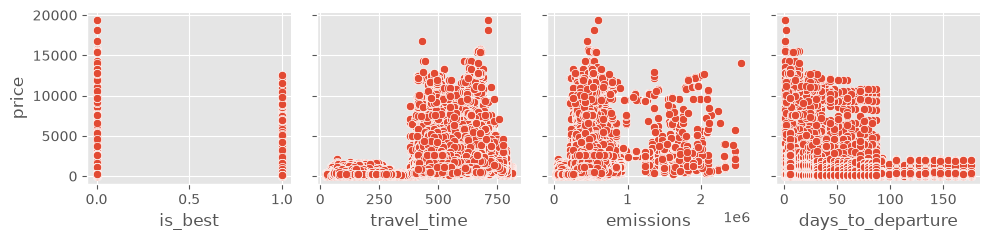

In [17]:
y = 'price'
features = data.drop(columns=[y]).select_dtypes(include="number").columns.to_list()
print(features)
sns.pairplot(data, x_vars=features, y_vars=[y])
plt.tight_layout()

In [ ]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> Because our target was continuous, we identified predicting the price as a regression task. We didn't pick classifiers, because we are not trying to classify anything, just predict the price. 3 main methods were used in modelling:
- **Ridge regression**
- **Lasso regression**
- **LightGBM**

**c. How do you measure success?**

Name the measure you report and say why it fits your goal. (For example accuracy, precision, recall, F1 or ROC AUC for classification, RMSE or MAE for regression - or something else that suits your project.)

In [ ]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> We measured success by 2 metrics:
- **MAE** - mean absolute error
- **RMSE** - root mean squared error

This fits our goal, because we wanted to measure how close to the actual price the models predict. MAE gives us the average miss in EUR, while RMSE shows us if our misses are usually bigger or smaller.

**d. What did you try, and how did you choose?**

Different settings, different parameters, several methods - say what you compared and on what basis you picked one.

In [ ]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> For Ridge and Lasso, we trained them with different `alpha` values, which is the size of the penalty these models apply for big coefficients. We measured MAE on the validation set on each run and picked the `alpha` which gave us the best result (the lowest MAE) for both. For Ridge, the best alpha was 30000, but for Lasso, 0.001. We decided to cut the Lasso tuning short because training it took way longer than others and the results were not promising at all.<br>

For LightGBM, which runs many decision trees with each tree correcting the errors of the one before it. Training was much simpler with this, because LGBM finds its best number of trees itself. We specified the learning rate of 0.05, max trees of 5000 and number of leaves to 127. We decided not to tune these settings because lowering learning rate would have just increased the number of trees, but probably wouldn't have corrected our result by much, because we already beat the baseline and training on 20 million rows took a lot of time. We chose the model LGBM itself found, around 829 trees. <br>

We trained all models on 2 sets of data: one with and one without the column `is_best`. This is because it could potentially be a data leakage problem, as mentioned above. We decided to keep models trained on data without this column, because it did improve predictions slightly, but not enough to risk a data leakage improving our scores.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 2 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> X hours<br>
<strong>Questions and comments (voluntary):</strong> Write here. You may include questions for the practice session, comments about the task, and a brief note on how you used help or AI.</p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">3. Evaluation (0.5 points)</h1>

</div>

This is **step 5**. Steps 4 and 5 are easy to confuse. Step 4 asks whether the method ran; step 5 asks whether the result is any good, and whether it answers the question you started from.

**a. Put the numbers side by side.**

Your baseline and your method, measured on data the method did not learn from. A small table or a plot is enough.

## Validation set results comparison with all models

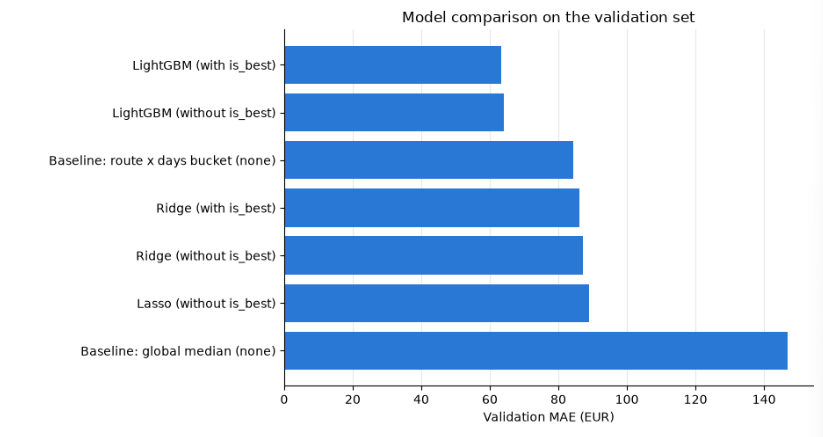

In [16]:
from IPython.display import Image

Image(filename="val_scores.png", width=700)

## Model results on the final test table after refitting on train+val on dataset without "is_best"

### We left Lasso out because it would have taken too long to re-train and it did not show potential

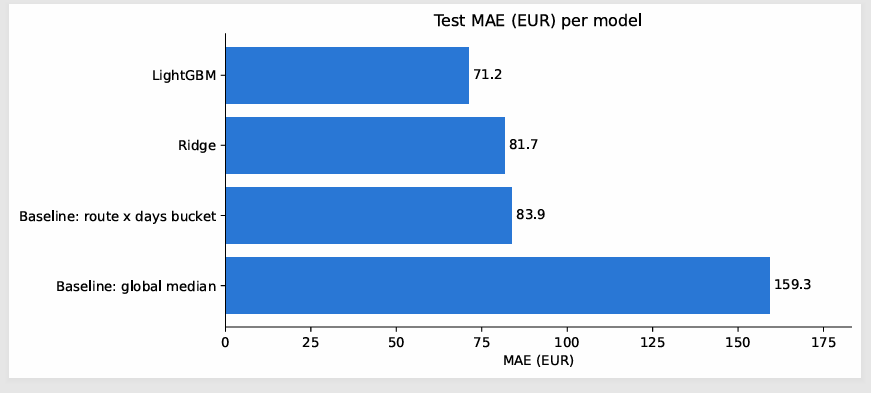

In [17]:
Image(filename="final_test.png", width=700)

## Table form of the first plot, shows also the RMSE

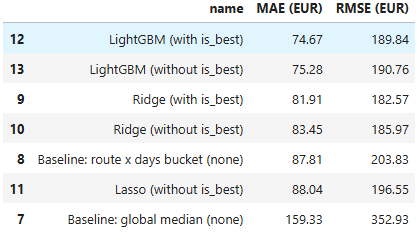

In [20]:
Image(filename="table_results.png", width=400)

## Table form of the second plot, shows also the RMSE

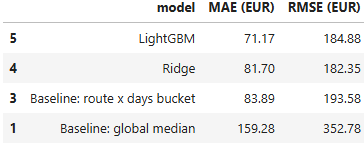

In [21]:
Image(filename="results_table_final.png", width=400)

<span style="color:#B3261E;"><strong>Answer:</strong></span> 2 plots and 2 tables tell the story themselves.

**b. What does your result actually mean for someone who would use it?**

A number on its own - "accuracy 0.87" - does not tell anyone whether the work was worth doing. Say what someone could now do that they could not do before, and whether your result is good enough for them to rely on.

In [ ]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> Our result shows that on average, the best model (LightGBM) misses by about 70 euros on average when predicting the price of a ticket. The actual signed error is -12.3, so the model actually undershoots by 12 euros on average.<br>

This still beats both baselines, both in MAE and signed error (-29.8 for the better baseline). This means that our model is capable of predicting the price more accurately than simple logic, but not by too much. This allows a person to see if waiting could potentially lower the price of a ticket, but it is not as good as one would hope, as the predicted price tends to be lower than the actual price, so the person should still account for a buffer of about 12 euros for the model mistake. Also, the model may produce bigger errors on more expensive tickets, so this model is best used on normal economy fligths with reasonable price ranges. <br>

All in all, this model is probably not good enough to rely on, but it is better than using a basic rule or logic, so it has potential in our eyes.

**c. What is the biggest threat to your conclusion?**

Too little data, a leak, a sample that does not represent what you claim, a measure that flatters your method - name the one that worries you most, and say how much it worries you.

In [ ]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> One thing that worries us the most is probably missing the seasonality effect. Because our data was collected over the span of 1 year, it is not enough to see how holidays actually affect prices. Since our train, validation and test data were all from different parts of the year, the model could not reliably take seasonality effects into account (e.g. a model trained on spring and summer data might not know how christmas or new years affects prices) this doesn't worry us overly much, but still might improve our results if we had data spanning several years.

**d. Did anything send you back to an earlier step?**

Look at the diagram at the top of this notebook. If something you found here made you change the data preparation, the method, or even the question itself, say which step you went back to and what you changed. If nothing did, say that.

In [ ]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> We established a different baseline in HW7 - buying 30 days in advance. We changed that baseline to reflect the mean price overall and per route and days to departure instead, since the baseline of buying 30 days in advance didn't really make sense once we started modelling. That was just a first idea.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 3 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> X hours<br>
<strong>Questions and comments (voluntary):</strong> Write here. You may include questions for the practice session, comments about the task, and a brief note on how you used help or AI.</p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">4. Towards the poster (0.5 points)</h1>

</div>

This is **step 6**, deployment. In a company this is where the result is put to use; on this course your poster and your repository are how your work reaches other people.

**These do not have to be the figures that end up on your poster.** You still have a week to make those. The point here is to work out *now* what in your project can actually be shown as a graph, and to have a first version in front of you that you can improve if needed.

**a. Two or three graphs from your project.**

Label the axes on each one. Then, in the answer below, write one sentence per graph saying what a reader should take from it.

In [ ]:
# TODO: first graph

In [ ]:
# TODO: second graph

In [ ]:
# TODO: third graph, if you have one

<span style="color:#B3261E;"><strong>Answer:</strong></span> Answer goes here.

**b. The front page of your repository.**

Write the README: the project name and the authors, the motivation and the goal, what is in which file, and how someone else would repeat your analysis. Paste it here as well.

<span style="color:#B3261E;"><strong>Answer:</strong></span> Answer goes here.

**c. The last week.**

What is left to do, who does it, and by when? The poster PDF, the project information form, the teamwork description form and access to your code repository are all due on Monday 7 December at 12:00.

<span style="color:#B3261E;"><strong>Answer:</strong></span> Answer goes here.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 4 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 0<br>
<strong>Time spent (voluntary):</strong> X hours<br>
<strong>Questions and comments (voluntary):</strong> Write here. You may include questions for the practice session, comments about the task, and a brief note on how you used help or AI.</p>

</div>

<div style='background-color:#FFF6DF; border-top:1px solid #E5CB91; border-left:4px solid #C7952D; border-radius:6px; padding:14px 18px; margin-top:26px; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Final check</h2>
<p style="color:#243038; margin:0.5em 0;">Before submitting, save and choose <strong>Kernel &gt; Restart &amp; Run All</strong>. Fix unexpected errors and check that all written answers remain visible.</p>

</div>

<div style='background-color:#FFF6DF; border-top:1px solid #E5CB91; border-left:4px solid #C7952D; border-radius:6px; padding:14px 18px; margin-top:26px; color:#243038;'>

<p style="color:#243038; margin:0.4em 0;">Thank you for your effort!</p>

</div>